# Autoregression

In [16]:
import numpy as np
import matplotlib.pyplot as plt

from course_utils.gradient_descent import perform_gradient_descent
from course_utils.plots import loss_landscape, plot_scatter_plot, mark_gradient_descent_path

Now we shall introduce **Autoregression**. Autoregression is a modelling approach in which previous observations of a variable are used to predict its future values.

In our previous linear regression examples, we approximated the relationship between two variables, $x$ and $y$. Here, we instead approximate the relationship between consecutive observations of the **same variable**, $x_{t-1}$ and $x_t$, or more generally, between $(x_{t-n}, x_{t-n+1}, \ldots, x_{t-1})$ and $x_t$.

We will begin with **linear autoregressive models**, which allow us to apply the linear regression techniques developed in the previous lessons to sequential data.

## Create Example Time Series and Loss Function

As we did in the previous lesson we will start with an example observation and a loss landscape.

Let's look at an example observation of the daily value of a stock (£).

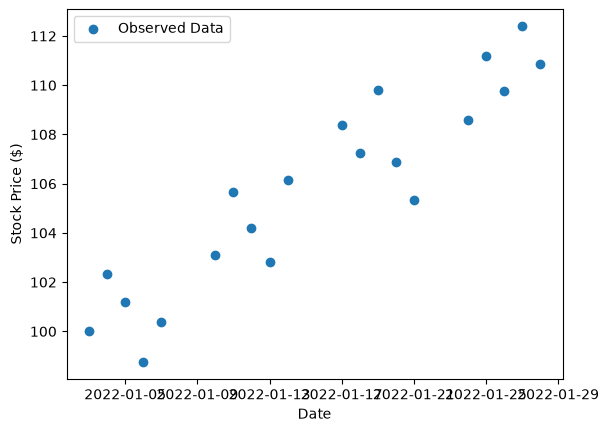

In [ ]:
time = np.busday_offset(
    np.datetime64("2022-01-03", "D"),
    np.arange(20)
)

stock_prices = np.array([
    100.00, 102.35, 101.20, 98.75, 100.40,
    103.10, 105.65, 104.20, 102.80, 106.15,
    108.40, 107.25, 109.80, 106.90, 105.35,
    108.60, 111.20, 109.75, 112.40, 110.85
], dtype=float)

plot_scatter_plot(
    x=time,
    y=stock_prices,
    x_label="Date",
    y_label="Stock Price ($)"
)

As in previous examples we will use the ***Mean Square Error (MSE)*** for our loss functon here which we define as:

In [18]:
def mse(y_observed: np.array, y_predicted: np.array) -> float:
    return np.mean((y_observed - y_predicted) ** 2)

## Visualise Possible Loss Values

Before we look at how to find the minimum possible loss value, let's simplify our problem by assuming that we only need the previous trading day's stock price to predict the next day's price.

This gives us an autoregressive model of order 1, or AR(1), because we use only one previous observation:

$$
\hat{x}_{d} = m \times x_{d-1} + b
$$

where:

- $\hat{x}_d$ is the predicted stock price on trading day $d$,
- $x_{d-1}$ is the observed stock price on the previous trading day,
- $m$ is the gradient,
- $b$ is the intercept.

Now lets define a reasonable set of possible values for $m$ and $b$ respectively and plot them against the result of the loss function for each pair of $m, b$. This is the ***Loss Landscape*** we plotted in previous lessons. 

However, this time our $x$ and $y$ values are the sequence of Stock Prices over time and the same sequences shifted by 1 day respectively. This is because our input is a day's stock price and the output is that price the day after.

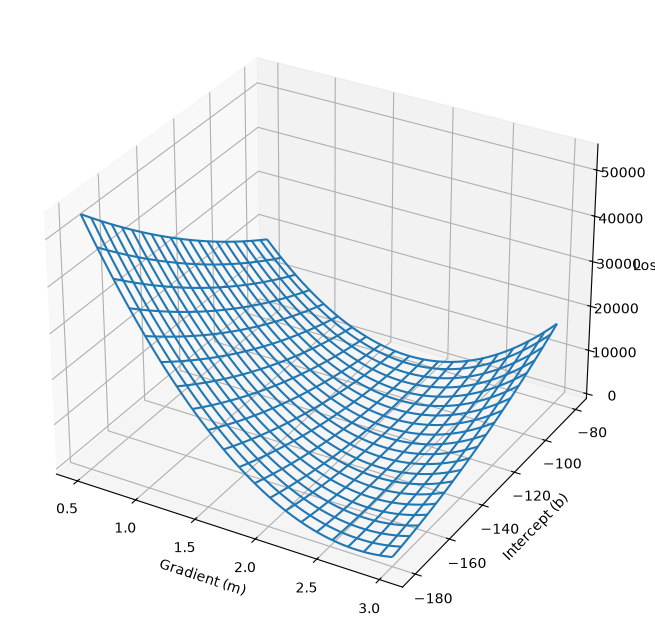

In [19]:
possible_m_values = np.linspace(0.5, 3, 100)
possible_b_values = np.linspace(-180, -80, 100)

fig, ax = loss_landscape(
    x_observed=stock_prices[:-1],
    y_observed=stock_prices[1:],
    possible_m_values=possible_m_values,
    possible_b_values=possible_b_values,
    loss_function=mse)

## Perform Gradient Descent on Our Observations

We have imported the gradient descent formula we defined in the previous lesson. We can now apply this to our observed stock prices and their corresponding next day values. 

In [20]:
initial_parameters = np.array([0.5, -130.0])
learning_rate = 0.000001
epochs = 5000

final_parameters, final_loss, parameter_history, loss_history = perform_gradient_descent(
    X_observed=stock_prices[:-1].reshape(-1, 1),
    y_observed=stock_prices[1:],
    initial_parameters=initial_parameters,
    learning_rate=learning_rate,
    epochs=epochs,
)

print("Using gradient descent with the following hyperparameters:")
print("Initial Parameters:")
print(f"Gradient (m): {initial_parameters[0]:.2f}")
print(f"Intercept (b): {initial_parameters[1]:.2f}")
print(f"Learning Rate: {learning_rate}")
print(f"Epochs: {epochs}")
print("We have found that the following parameter values minimise the loss when fitting our Linear Regression to our observed data:")
print(f"Gradient (m): {final_parameters[0]:.2f}")
print(f"Intercept (b): {final_parameters[1]:.2f}")
print(f"Loss: {final_loss:.2f}")

Using gradient descent with the following hyperparameters:
Initial Parameters:
Gradient (m): 0.50
Intercept (b): -130.00
Learning Rate: 1e-06
Epochs: 5000
We have found that the following parameter values minimise the loss when fitting our Linear Regression to our observed data:
Gradient (m): 2.24
Intercept (b): -129.98
Loss: 34.15


### Visualising Gradient Descent on Our Loss Landscape

Now we have performed gradient descent, and recorded the progress along the way, we can visualise this on our loss landscape.

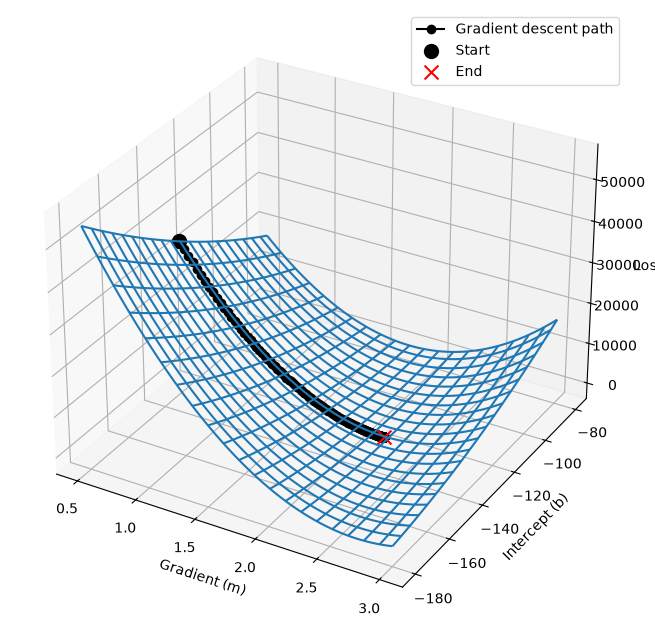

In [21]:
m_history = [p[0] for p in parameter_history]
b_history = [p[1] for p in parameter_history]

fig, ax = loss_landscape(
    x_observed=stock_prices[:-1],
    y_observed=stock_prices[1:],
    possible_m_values=possible_m_values,
    possible_b_values=possible_b_values,
    loss_function=mse
)

mark_gradient_descent_path(ax, m_history, b_history, loss_history)

### Plotting Our Autoregression

Finally, we can plot the result of our autoregressive model against out observations:

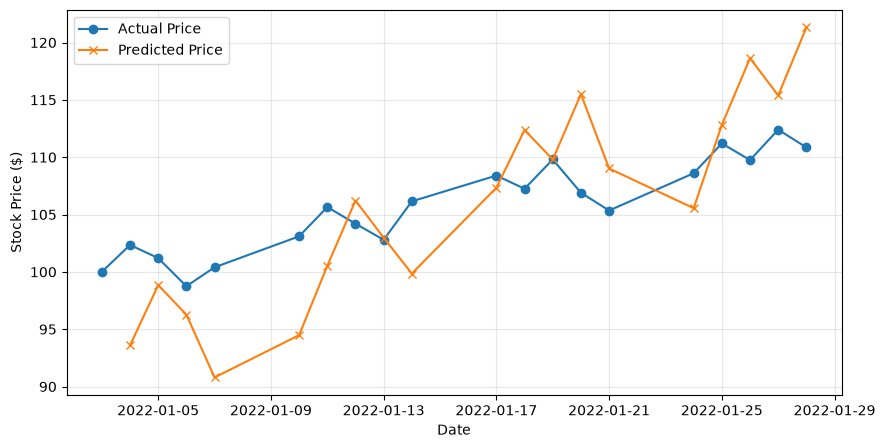

In [ ]:
m = final_parameters[0]
b = final_parameters[1]

predicted_prices = m * stock_prices[:-1] + b

plt.figure(figsize=(10, 5))

plt.plot(
    time,
    stock_prices,
    marker="o",
    label="Actual Price"
)

plt.plot(
    time[1:],
    predicted_prices,
    marker="x",
    label="Predicted Price"
)

plt.xlabel("Date")
plt.ylabel("Stock Price ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()